<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Repeated Reshare Ratio Report

We asked the question of how often a user reshare the same post multiple times and intended to use that to determine if this repeated reshare behavior should be allowed in the simulator.

This notebook is a **report runner**. All heavy processing happens in `repeated_reshare_report_spark.py` using **Spark-first** aggregation over Parquet.


## Folder placement

- **Current location**: `analyses/calibration/user/repeated_reshare_ratio/`


## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: Bluesky Firehose
- **Time range**: `2025-09-30` to `2025-11-01`
- **Access / documentation link**: Data collection was done with [`osome-iu/osome-bluesky-streamer`](https://github.com/osome-iu/osome-bluesky-streamer), an archive can be requested by contacting [OSoMe IU](https://osome.iu.edu/resources/data-resources).
- **Raw files / tables used**: Place Bluesky Firehose `.json.gz` files in `./data/raw`
- **Preprocessing steps**: Filtered for reshare create events.
- **Notes / limitations**: This was done on only 1 month of data, missing potential repeats where the first reshare happened outside of data range.


In [1]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd()))

import repeated_reshare_report_spark as rr

def _relpath(value):
    try:
        p = Path(value)
    except Exception:
        return value
    try:
        return str(p.resolve().relative_to(Path.cwd().resolve()))
    except Exception:
        return p.name

def show_cfg(cfg):
    default = rr.Config(base_data_dir=cfg.base_data_dir)
    cfg_dict = cfg.__dict__.copy()
    default_dict = default.__dict__.copy()
    diff = {k: v for k, v in cfg_dict.items() if default_dict.get(k) != v}
    diff["base_data_dir"] = cfg_dict.get("base_data_dir")
    for key, value in list(diff.items()):
        if key == "parquet_glob" and isinstance(value, str):
            diff[key] = _relpath(value)
        if isinstance(value, Path):
            diff[key] = _relpath(value)
    return diff


## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: `N/A`
- **What it adds**: Helps us understand if the simulator should allow repeated reshares
- **Code location**: `N/A` Related to user behaviors and recommender system
- **Design rationale**: Trace for x-days periods, the % of users who has done any repeated reshares. This version does not track a fixed set of users through time, which makes it harder to interpret the results. For future versions, it should either 1) pick a fixed set of users and observe user ratio over time, or 2) focus on activity ratio over time. However, one of the limitation remains as we don't know the true FIRST OCCURRENCE of a user's reshare. Which we either assume that users only do repeated reshare on reshares created relatively recently, or interpret the ratios as than chance of that happening within a certain timeframe, or take that as a good enough representation.


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.



## 3) Analysis / calibration method

Document how you transform the data into model parameters or behaviors.

- **Features extracted**: Per-day `(author, target_uri)` pairs and repeated-reshare ratios by definition.
- **Estimation / fitting**: Ratio calculations + cumulative fit params from the report output.
- **Validation**: N/A


In [2]:
import os
os.environ["SPARK_LOCAL_DIRS"] = "/media/volume/sim-analysis-data/spark_tmp"

cfg = rr.Config(
    base_data_dir=Path("/media/volume/sim-analysis-data/data_repeated_reshare"),
    raw_dir_override=Path("/media/volume/sim-analysis-data/raw/bsky"),
    spark_local_dir=Path("/media/volume/sim-analysis-data/spark_tmp"),
    # analysis_start_day="2025-10-01",
    # analysis_end_day="2025-10-11",
    series_mode="cumulative",  # or "windows" or "both"
    # enabled_kinds=("repost", "like"),
    enabled_kinds=("repost",),
    # enabled_kinds=("like",),
    # log_progress=True,
    # (SQLite state caching removed; Spark-first + parquet table caching is used instead)
    # progress_every_batches=25,
    # progress_every_days=20,
    # compute_sliding_series=False,
    # spark_master="local[8]",
    # spark_sql_shuffle_partitions=2000,
    # spark_shuffle_compress=False,
    # write_window_tables=True,
    # spark_driver_memory="24g",
    # spark_executor_memory="24g",
    # use_cached_tables=True,  # skip Spark scan if cached parquet tables exist
    # parquet_dir_override=Path("/path/to/parquet"),
    # intermediate_dir_override=Path("/path/to/intermediate"),  # caches go under <intermediate>/tables
)
# show_cfg(cfg)



In [3]:
# Optional explicit prep check (report generation runs this automatically)
# rr.ensure_parquet(cfg)


[repeat-report] prepare parquet step started
No new or changed raw files. Nothing to do.
[repeat-report] prepare parquet step finished
[repeat-report] using cached parquet tables (skipping Spark scan)
[repeat-report] building cumulative/window series
Whole-period ratios by kind:
     kind  total_users  repeat_users_pct_of_total  repeat_pairs_pct
0  repost      1686739                   0.070356          0.006352


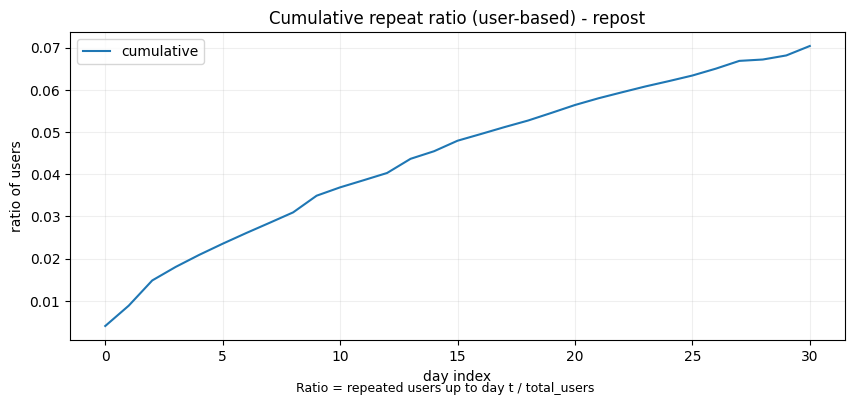

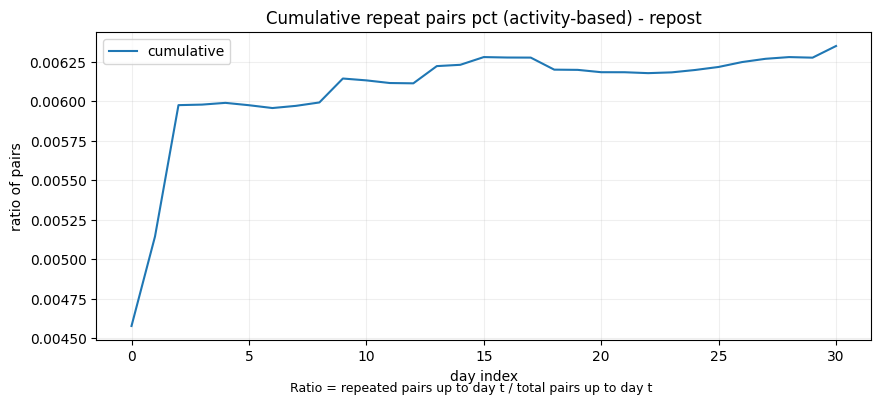

Sliding series disabled (compute_sliding_series=False).
Definitions:
- total_users: shared denominator across kinds (users with >=1 create repost OR like in range)
- users_with_kind: per-kind denominator (users with >=1 create for that specific kind)
- repeat_users_pct_of_total: users with >=2 creates for same pair / total_users (user-based)
- repeat_pairs_pct: pairs with >=2 creates / all pairs within kind (activity-based)
- repeat_day uses the later create day and is not restricted to same-day repeats


,kind,a,b,c,r2
0,repost,0.070356,0.085869,0.102052,0.883802


In [4]:
# Run report + plots in one call
report = rr.generate_report_with_plots(cfg, show=True)

print("Definitions:")
print("- repeat_users_pct_of_total: users with >=2 creates for same pair / total_users within kind")
print("- repeat_pairs_pct: user-reshared_content pairs with >=2 creates / all pairs within kind")

report["summary"]
report["cumulative_fit_params"]


## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure Spark temp dir and data paths in the config are valid for your environment.
2. Ensure Bluesky Firehose `.json.gz` files are in the data path configured
3. Run this notebook top-to-bottom to generate the report tables and plots.


In [5]:
# Optional: call without rendering inline and save plot files
rr.generate_report_with_plots(cfg, show=False, save_dir=cfg.intermediate_dir / "plots")


[repeat-report] prepare parquet step started
No new or changed raw files. Nothing to do.
[repeat-report] prepare parquet step finished
[repeat-report] using cached parquet tables (skipping Spark scan)
[repeat-report] building cumulative/window series
Whole-period ratios by kind:
     kind  total_users  repeat_users_pct_of_total  repeat_pairs_pct
0  repost      1686739                   0.070356          0.006352
Sliding series disabled (compute_sliding_series=False).


{'summary':      kind      pairs  repeat_pairs  users_with_kind  repeat_users  \
 0  repost  105853736        672355          1686739        118673   
 
    total_users  repeat_users_pct_of_total  repeat_users_pct_of_kind  \
 0      1686739                   0.070356                  0.070356   
 
    repeat_pairs_pct  
 0          0.006352  ,
 'notes': {'total_users': 1686739},
 'cumulative_repeat_series':       kind        day  day_index  repeat_users  total_users     ratio
 0   repost 2025-10-01          0          6819      1686739  0.004043
 1   repost 2025-10-02          1         14947      1686739  0.008861
 2   repost 2025-10-03          2         25015      1686739  0.014830
 3   repost 2025-10-04          3         30427      1686739  0.018039
 4   repost 2025-10-05          4         35233      1686739  0.020888
 5   repost 2025-10-06          5         39688      1686739  0.023529
 6   repost 2025-10-07          6         43944      1686739  0.026053
 7   repost 2025-10-08

## 4) Results

Summarize the outcome and attach key plots/tables. If large, don't upload to repo.

- **Outputs / artifacts**: Report summary tables, cumulative fit params, and plots above
- **Where results are saved**: in notebook
- **Key takeaways**: Repeated reshares happens very rarely. However, since most of the mainstream social media platform allow this, we decided to allow that in the simulator. Might need to calibrate with more data in the future.


## 5) Change log

Record updates so future changes are traceable.

- `2026-03-04`: Initial assembly of report.
